- **Session 1 assignment**
- **Mehrdad Mohammadian**

# 1. California cities (Water area leaders)
Find the 5 California cities with the largest water area.

Load and inspect california_cities.csv.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

cities = pd.read_csv(
    "../2.california_cities/california_cities.csv", index_col=0)
print("shape:", cities.shape)
cities.head()

shape: (482, 13)


,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


Check the data types and missing values in the water-area columns.

In [7]:
water_area_columns = ["area_water_km2", "area_water_sq_mi"]
print("--- data types:")
print(cities[water_area_columns].dtypes.astype(str), end="\n\n")
print("--- missing values:")
print(cities[water_area_columns].isnull().sum())

--- data types:
area_water_km2      float64
area_water_sq_mi    float64
dtype: object

--- missing values:
area_water_km2      4
area_water_sq_mi    1
dtype: int64


As we can see, there are 4 missing values for "area_water_km2" column. But we are able to calculate them by converting their "area_water_sq_mi" into "are_water_km2".

In [8]:
cities["area_water_km2"] = cities["area_water_km2"].fillna(
    cities["area_water_sq_mi"] * 2.58999)

In [9]:
print("--- missing values:")
print(cities[water_area_columns].isnull().sum())

--- missing values:
area_water_km2      0
area_water_sq_mi    1
dtype: int64


Now, we do not have any missing value in the "area_water_km2".

Rank the cities by `area_water_km2` and display the top five.

In [10]:
top_5_cities = cities.nlargest(5, "area_water_km2")[["city", "area_water_km2"]]
top_5_cities

,city,area_water_km2
370,SanFrancisco,479.19995
367,SanDiego,122.27000
239,LosAngeles,88.00000
285,NewportBeach,75.55700
93,Coronado,64.06200


Create a clearly labeled horizontal bar chart of the 5 cities and their water areas.

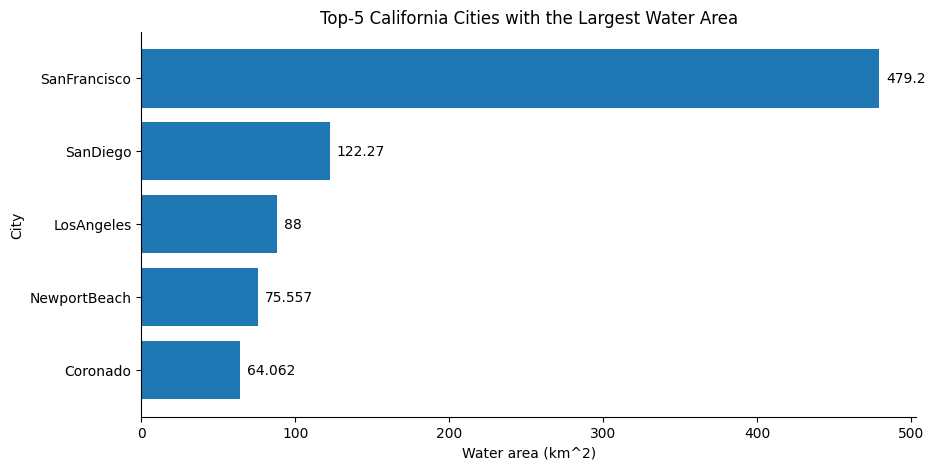

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    top_5_cities["city"],
    top_5_cities["area_water_km2"],
)

ax.invert_yaxis()
ax.set_xlabel("Water area (km^2)")
ax.set_ylabel("City")
ax.set_title("Top-5 California Cities with the Largest Water Area")
ax.bar_label(bars, padding=5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

# 2. Billionaires (Other industries)

Load and inspect Billionaire.csv.

In [12]:
billionaires = pd.read_csv("../3.billionaires/Billionaire.csv")
print("shape:", billionaires.shape)
billionaires.head()

shape: (2755, 7)


,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


check for missing values before counting industries.

In [13]:
print("--- missing values:")
billionaires.isna().sum()

--- missing values:


Name         0
NetWorth     0
Country      0
Source       0
Rank         0
Age         79
Industry     0
dtype: int64

there is no missing value in the "industry" column so we can safely continue to find the largest industries!

Count billionaires in each industry and sort the counts from largest to smallest.

In [14]:
industry_counts = billionaires["Industry"].value_counts(
).sort_values(ascending=False)
industry_counts.rename("billionaires").to_frame()

,billionaires
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


- Keep the first 10 industries as separate categories.
- Add an Other category containing the combined count of all remaining industries.

In [15]:
top_industries = industry_counts.head(10).copy()
top_industries["Other"] = industry_counts.iloc[10:].sum()
top_industries = top_industries.sort_values(ascending=False)
top_industries.rename("billionaires").to_frame()

,billionaires
Industry,
Other,377
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188


Display the final distribution as a labeled pie chart.

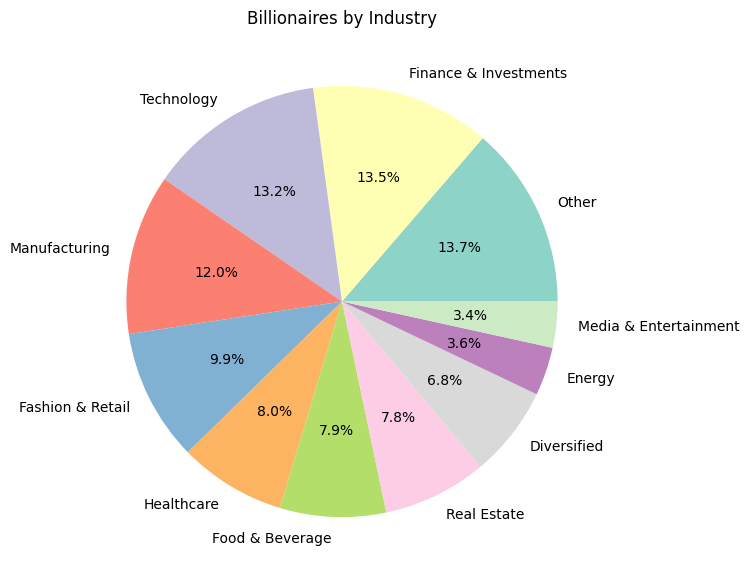

In [16]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.pie(
    top_industries.values,
    labels=top_industries.index,
    colors=plt.cm.Set3.colors,
    autopct="%1.1f%%",
)
ax.set_title("Billionaires by Industry")
plt.show()

# 3. Online retail (Monthly Retention Rate)

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

retail = pd.read_csv(
    "../5.online_retail/OnlineRetail.csv", encoding="latin1")

let's filter the dataset to only include purchases from the UK, as it has the highest number of transactions.

In [18]:
retail = retail.query("Country=='United Kingdom'").reset_index(drop=True)
print("shape:", retail.shape)
retail.head()

shape: (495478, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [19]:
retail.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133600
Country             0
dtype: int64

let's convert InvoiceDate to datetime, and drop rows with missing CustomerID

In [20]:
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])
retail = retail.dropna(subset=["CustomerID", "InvoiceDate"]).copy()
print("shape:", retail.shape)

shape: (361878, 8)


Create a customer-by-month activity table with pd.crosstab().

As we want a customer-by-month activity table, we need to assign each purchase to its calendar month.

In [21]:
retail["Month"] = retail["InvoiceDate"].dt.to_period("M")
retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12


Use `pd.crosstab()` to build a customer-by-month activity table. Each cell is True when the customer purchased in that month. The crosstab columns are already sorted by month in this dataset.


In [22]:
current_month_activity = pd.crosstab(
    retail["CustomerID"], retail["Month"]
).gt(0)

current_month_activity.head()

Month,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
CustomerID,,,,,,,,,,,,,
12346.0,False,True,False,False,False,False,False,False,False,False,False,False,False
12747.0,True,True,False,True,False,True,True,False,True,False,True,True,True
12748.0,True,True,True,True,True,True,True,True,True,True,True,True,True
12749.0,False,False,False,False,False,True,False,False,True,False,False,True,True
12820.0,False,True,False,False,False,False,False,False,False,True,True,False,True


Calculate the customers who were active both in the current month and in the previous month.

We can shift the "customer_month_activity" values by one month to see if the each customer was active in the previous month.

In [23]:
monthly_active_customers = current_month_activity.sum(axis=0)
monthly_active_customers.to_frame().rename(
    columns={0: "Active in the current month"})

,Active in the current month
Month,
2010-12,871
2011-01,684
2011-02,714
2011-03,923
2011-04,817
2011-05,985
2011-06,943
2011-07,899
2011-08,867


In [24]:
previous_month_activity = current_month_activity.shift(
    axis=1, fill_value=False
)

previous_month_activity.head()

Month,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
CustomerID,,,,,,,,,,,,,
12346.0,False,False,True,False,False,False,False,False,False,False,False,False,False
12747.0,False,True,True,False,True,False,True,True,False,True,False,True,True
12748.0,False,True,True,True,True,True,True,True,True,True,True,True,True
12749.0,False,False,False,False,False,False,True,False,False,True,False,False,True
12820.0,False,False,True,False,False,False,False,False,False,False,True,True,False


In [25]:
both_current_and_previous_activity = (
    current_month_activity & previous_month_activity
).sum()

both_current_and_previous_activity.to_frame().rename(
    columns={0: "Active both in the previous month and the current month"})

,Active both in the previous month and the current month
Month,
2010-12,0
2011-01,322
2011-02,263
2011-03,305
2011-04,310
2011-05,369
2011-06,417
2011-07,379
2011-08,391


As we are not able to calculate the retention rate for the first month in the dataset (i.e 2010-12), we need to remove it.

In [26]:
current_month_activity = current_month_activity.columns[1:]

Store the results in a DataFrame with the month, total customers, retained customers, and retention rate. We compute the retention rate using this formula:

$
Monthly Retention Rate = Retained Customers from Previous Month / Total Active Customers
$

In [27]:
monthly_retention = pd.DataFrame({
    "Month": current_month_activity,
    "TotalCustomers": monthly_active_customers.loc[current_month_activity].to_numpy(),
    "RetainedCustomers": both_current_and_previous_activity.loc[current_month_activity].to_numpy(),
})

monthly_retention["RetentionRate"] = (
    monthly_retention["RetainedCustomers"] /
    monthly_retention["TotalCustomers"]
)

monthly_retention.style.format({"RetentionRate": "{:.1%}"})

,Month,TotalCustomers,RetainedCustomers,RetentionRate
0,2011-01,684,322,47.1%
1,2011-02,714,263,36.8%
2,2011-03,923,305,33.0%
3,2011-04,817,310,37.9%
4,2011-05,985,369,37.5%
5,2011-06,943,417,44.2%
6,2011-07,899,379,42.2%
7,2011-08,867,391,45.1%
8,2011-09,1177,417,35.4%
9,2011-10,1285,502,39.1%


Create a clearly labeled line chart of the monthly retention rate. Exclude December 2011 from the final comparison because the dataset is incomplete for that month.

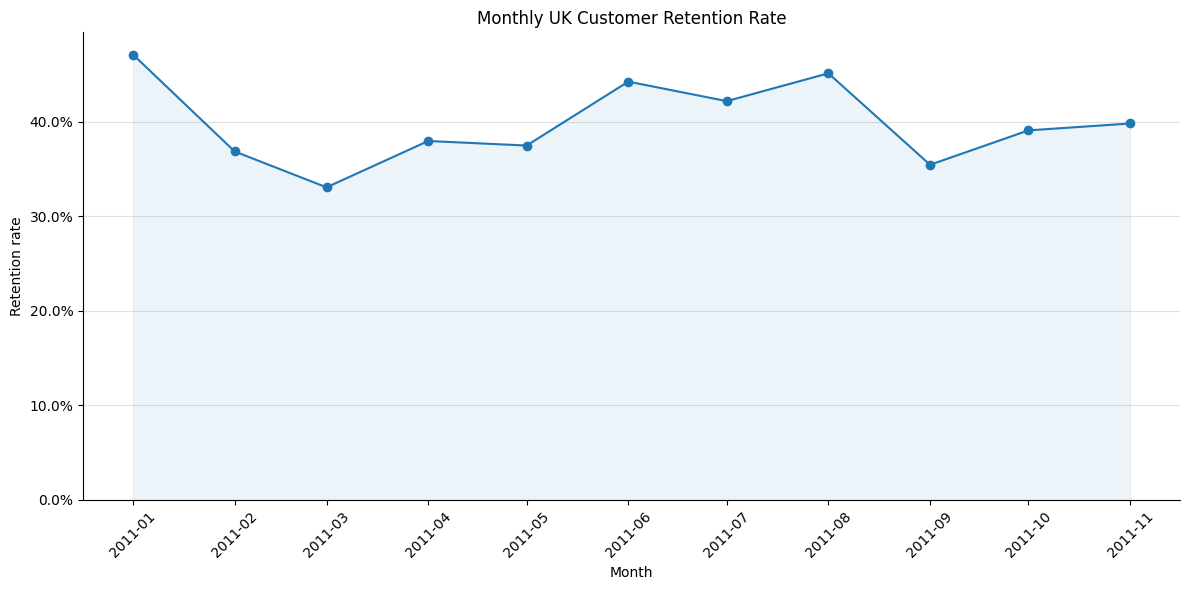

In [28]:
chart_data = monthly_retention.loc[monthly_retention["Month"] != "2011-12"]

x = chart_data["Month"].dt.to_timestamp().to_numpy()
y = chart_data["RetentionRate"].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(x, y, 0, color="tab:blue", alpha=0.08)
ax.plot(x, y, marker="o", color="tab:blue")
ax.set_title("Monthly UK Customer Retention Rate")
ax.set_xlabel("Month")
ax.set_ylabel("Retention rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()